# Learned Features: ResNet-18, CLIP, and DINOv2

SIFT recognizes this particular Matterhorn, but not mountains in general, and no hand-designed
feature separates "snow-covered peak" from "white building under a blue sky". Neural networks
learn their features from data instead. This notebook follows two book sections. *Learned
Features: CNNs* opens a trained network, ResNet-18, and turns it into a feature extractor.
*Transformer Embeddings for Image Search* adds CLIP, which places images and texts in one space,
and DINOv2, which learns visual similarity from images alone. At the end, the Matterhorn query
runs through every generation of features of this chapter.

**Learning goals:**
- Inspect the 64 learned first-layer filters of ResNet-18 and the feature maps of its stages
- Read the network's class probabilities and see where they stop being useful
- Compute an embedding by global average pooling and compare embeddings from different stages
- Search the collection with ResNet-18 embeddings and train a linear probe with six labeled photos
- Compute the contrastive loss of CLIP on a batch of three image-caption pairs
- Detect near-duplicates with CLIP, DINOv2, and ResNet-18
- Compare color histograms, SIFT, ResNet-18, DINOv2, and CLIP on one query, and run text queries

**Prerequisites:** demos ch10-01 to ch10-03; Chapter 5 (text embeddings, bi-encoders); Chapter 6
(vector search); Chapter 2 (precision at k)

**Data and models:** the collection of 45 photos from the book (43 photos from Wikimedia Commons
are downloaded on the first run, about 16 MB; `data/images/ch10_collection.json` lists authors
and licenses). Three pretrained models from Hugging Face are downloaded on the first run, about
0.7 GB in total: `microsoft/resnet-18`, `openai/clip-vit-base-patch32`, and
`facebook/dinov2-small`. A laptop CPU is enough; the notebook runs in a few minutes.

## Setup

`Embedders` in `ch10_features.py` loads the three models and returns embeddings of unit length.
The notebook also reaches into the ResNet-18 model directly to look at its filters and feature
maps.

In [1]:
import textwrap
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageEnhance, ImageOps
from sklearn.linear_model import LogisticRegression

from shared.display import print_table, display_md
from ch10_features import (PHOTOS, DATA, Embedders, load_collection, load_image, lab_histogram,
                           lab_histogram_fast, lab_similarity_matrix, quadratic, sift_features, sift_score,
                           crop_32)

E = Embedders()
photos = {n: Image.open(DATA / f).convert("RGB") for n, (f, _) in PHOTOS.items()}     # PIL images
titles = {name: title for name, (_, title) in PHOTOS.items()}
query = photos["matterhorn"]

collection = load_collection()
ids = [it["id"] for it in collection]
images = [load_image(it["path"]) for it in collection]           # longest side at most 1280 pixels
display_md(f"Collection: **{len(collection)} photos**, {sum(it['is_matterhorn'] for it in collection)} of the "
           f"Matterhorn, {sum(it['is_mountain'] for it in collection)} of a mountain.")

Collection: **45 photos**, 8 of the Matterhorn, 20 of a mountain.

## Part 1: ResNet-18

ResNet-18 was trained to sort the 1.28 million photos of ImageNet into 1,000 classes such as
"alp", "mosque", and "tennis racket". Nothing in its training tells it about edges, colors, or
textures. It only receives a photo and the correct class.

In [2]:
n_params = sum(p.numel() for p in E.resnet_model.parameters())
display_md(f"ResNet-18 has **{n_params / 1e6:.1f} million parameters** and "
           f"**{E.resnet_model.config.num_labels:,} output classes**.")

ResNet-18 has **11.7 million parameters** and **1,000 output classes**.

### What the first layer learns

The first layer consists of 64 filters of 7 by 7 pixels with three color channels each. It applies
them exactly like the Sobel kernels of demo ch10-02, but nobody chose the weights. We show each
filter as a small color image, with its weights scaled to the full range of brightness.

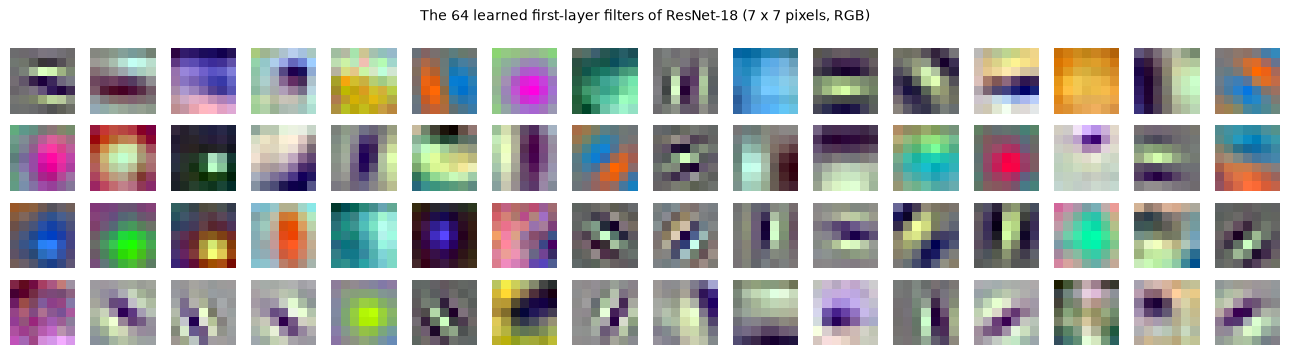

In [3]:
W = E.resnet_model.resnet.embedder.embedder.convolution.weight.detach().numpy()     # 64 x 3 x 7 x 7
fig, axes = plt.subplots(4, 16, figsize=(13, 3.6))
for ax, f in zip(axes.ravel(), W):
    f = f.transpose(1, 2, 0)                                        # 7 x 7 x 3
    ax.imshow((f - f.min()) / (f.max() - f.min()), interpolation="nearest")
    ax.axis("off")
plt.suptitle(f"The {W.shape[0]} learned first-layer filters of ResNet-18 ({W.shape[2]} x {W.shape[3]} pixels, RGB)",
             fontsize=10)
plt.tight_layout()
plt.show()

Many filters are oriented edge detectors, a dark and a bright half at some angle, like a Sobel
kernel. Others are stripe patterns of several orientations and widths, like Gabor filters. A
third group responds to color: blobs of one color, and filters that compare two opposing colors,
such as orange against blue or magenta against green, which echo the $a$ and $b$ axes of CIE Lab.
Trained only to name objects, the network rediscovered the building blocks of demos ch10-01 and
ch10-02.

### Feature maps: from edges to objects

Each filter produces a **feature map**, an image that is bright where the filter's pattern occurs.
The network sees a center crop of 224 by 224 pixels. Every stage halves the resolution and
increases the number of feature maps.

In [4]:
with torch.no_grad():
    out = E.resnet_outputs(query)
stages = out.hidden_states                                          # stem, then stages 1 to 4
print_table([[("stem (first layer and pooling)" if i == 0 else f"stage {i}"), s.shape[1], f"{s.shape[2]} x {s.shape[3]}"]
             for i, s in enumerate(stages)],
            headers=["Output", "Feature maps", "Size of each map"])

| Output                         |   Feature maps | Size of each map   |
|:-------------------------------|---------------:|:-------------------|
| stem (first layer and pooling) |             64 | 56 x 56            |
| stage 1                        |             64 | 56 x 56            |
| stage 2                        |            128 | 28 x 28            |
| stage 3                        |            256 | 14 x 14            |
| stage 4                        |            512 | 7 x 7              |

We show the input crop and, for stage 1 and stage 4, the six feature maps with the highest mean
activation.

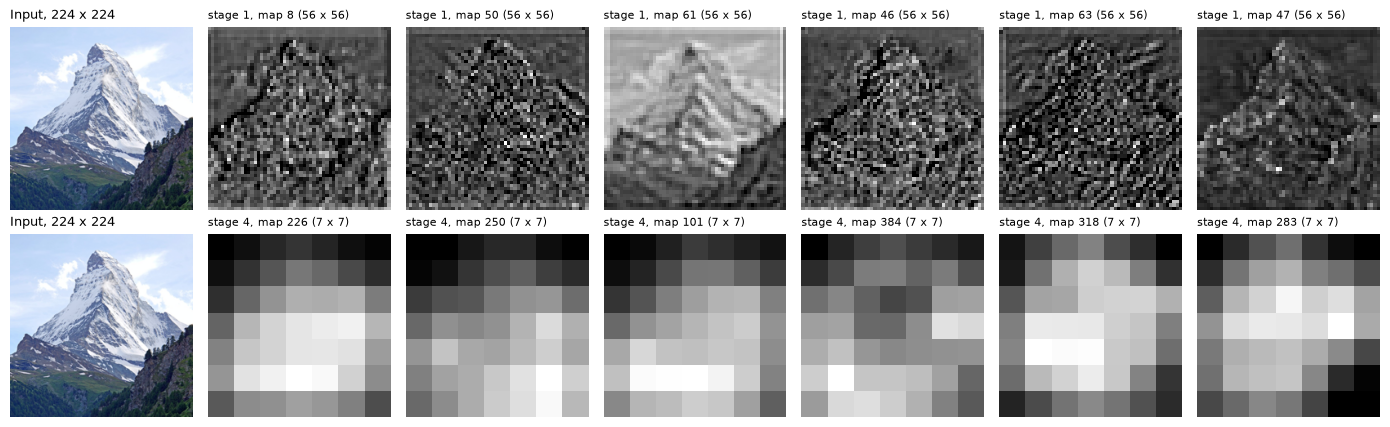

In [5]:
pixels = E.resnet_processor(images=query, return_tensors="pt")["pixel_values"][0].numpy().transpose(1, 2, 0)
mean, std = np.array(E.resnet_processor.image_mean), np.array(E.resnet_processor.image_std)
seen = np.clip(pixels * std + mean, 0, 1)                           # undo the normalization for display

fig, axes = plt.subplots(2, 7, figsize=(14, 4.4))
for r, stage in enumerate((1, 4)):
    maps = stages[stage][0].numpy()
    axes[r, 0].imshow(seen)
    axes[r, 0].set_title("Input, 224 x 224", fontsize=9, loc="left")
    for c, k in enumerate(np.argsort(-maps.mean((1, 2)))[:6], 1):
        axes[r, c].imshow(maps[k], cmap="gray", interpolation="nearest")
        axes[r, c].set_title(f"stage {stage}, map {k} ({maps.shape[1]} x {maps.shape[2]})", fontsize=8, loc="left")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

The maps of stage 1 still look like filtered versions of the photo: they respond to edges, bright
areas, or textures, and the mountain is easy to recognize. The maps of stage 4 have only 7 by 7
values. Each value depends on most of the image, and the maps no longer show the photo; they
record which learned patterns occur where.

### What the network answers

At the top, ResNet-18 averages each of the 512 final feature maps into a single number, and a
fully connected layer maps the 512 values to 1,000 class scores, which a softmax turns into
probabilities.

In [6]:
rows = []
for n, im in photos.items():
    rows.append([titles[n]] + [f"{c} ({p:.1%})" for c, p in E.resnet_top(im, k=2)])
print_table(rows, headers=["Photo", "Most probable class", "Second"])

| Photo         | Most probable class     | Second               |
|:--------------|:------------------------|:---------------------|
| Matterhorn    | alp (77.9%)             | valley, vale (21.3%) |
| Taj Mahal     | mosque (98.8%)          | palace (0.4%)        |
| Roger Federer | racket, racquet (34.5%) | baseball (14.6%)     |

The answers match the book. The Taj Mahal is a mausoleum, but ImageNet has no such class, so the
network answers "mosque" with high confidence: it can only choose among the classes it was
trained on.

### The second-to-last layer as an embedding

The 512 values before the last layer are the network's description of the image, from which it
computes all class scores with a single linear layer. **Global average pooling** computes them
from the $K = 512$ feature maps $F_k$ of size $H \times W = 7 \times 7$:

$$e_k = \frac{1}{H W} \sum_{x=1}^{W} \sum_{y=1}^{H} F_k(x, y) \qquad k = 1, \ldots, K$$

We compute the average by hand and check that the classifier's linear layer turns it into the
same class scores as the full network.

In [7]:
with torch.no_grad():
    F = stages[-1][0]                                               # 512 x 7 x 7
    e = F.mean(dim=(1, 2))                                          # global average pooling: 512 values
    logits = E.resnet_model.classifier[1](e)                        # the last layer: 512 -> 1000
display_md(f"Embedding: **{e.shape[0]} values**, all at least 0 (smallest: {e.min():.3f}), because the "
           f"activations before pooling pass a ReLU. Largest difference to the class scores of the full "
           f"network: {(logits - out.logits[0]).abs().max():.1e}.")

Embedding: **512 values**, all at least 0 (smallest: 0.000), because the activations before pooling pass a ReLU. Largest difference to the class scores of the full network: 0.0e+00.

Which stage gives a useful embedding? We average the feature maps of stage 1 and of stage 4 and
compare the three photos by cosine similarity.

In [8]:
def cosine_table(stage):
    v = {n: E.resnet(im, stage) for n, im in photos.items()}
    return [v["matterhorn"] @ v["taj_mahal"], v["matterhorn"] @ v["federer"], v["taj_mahal"] @ v["federer"]]

print_table([[f"stage {s} ({stages[s].shape[1]} maps)"] + cosine_table(s) for s in (1, 4)],
            headers=["Embedding from", "Matterhorn and Taj Mahal", "Matterhorn and Federer", "Taj Mahal and Federer"],
            floatfmt=".3f")

| Embedding from     |   Matterhorn and Taj Mahal |   Matterhorn and Federer |   Taj Mahal and Federer |
|:-------------------|---------------------------:|-------------------------:|------------------------:|
| stage 1 (64 maps)  |                      0.988 |                    0.981 |                   0.984 |
| stage 4 (512 maps) |                      0.487 |                    0.449 |                   0.510 |

Averaged over the image, the 64 maps of stage 1 make every photo look alike: every photo contains
edges and colors of all kinds. Only the last stage separates them. Its cosine similarities are
never negative, because the averaged activations are never negative; only the ranking and the
differences between candidates carry information.

### What the embedding finds

We compare the Matterhorn photo with the 45 photos of the collection, once by the cosine
similarity of the ResNet-18 embeddings and once by the quadratic distance of the 125-bin Lab
histograms of demo ch10-01.

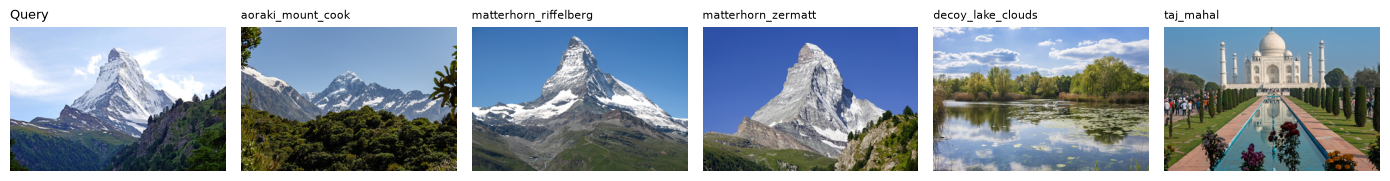

| Photo                 |   ResNet-18 cosine |   ResNet-18 rank |   Color histogram rank |
|:----------------------|-------------------:|-----------------:|-----------------------:|
| aoraki_mount_cook     |              0.924 |                1 |                     21 |
| matterhorn_riffelberg |              0.910 |                3 |                     18 |
| matterhorn_zermatt    |              0.883 |                6 |                     26 |
| decoy_lake_clouds     |              0.527 |               27 |                      5 |
| taj_mahal             |              0.487 |               31 |                     13 |

In [9]:
def rank_of(scores, i):
    """Rank of item i when higher scores come first (ties share the better rank)."""
    return 1 + int((scores > scores[i]).sum())

A = lab_similarity_matrix()
H = [lab_histogram(np.asarray(im)) for im in images]
h_q = lab_histogram(np.asarray(query))
V_res = np.array([E.resnet(im) for im in images])
s_res = V_res @ E.resnet(query)
s_hist = -np.array([quadratic(h_q, h, A) for h in H])               # smaller distance = higher score

shown = ["aoraki_mount_cook", "matterhorn_riffelberg", "matterhorn_zermatt", "decoy_lake_clouds", "taj_mahal"]
fig, axes = plt.subplots(1, 6, figsize=(14, 2.3))
axes[0].imshow(crop_32(query))
axes[0].set_title("Query", fontsize=9, loc="left")
for ax, cid in zip(axes[1:], shown):
    i = ids.index(cid)
    ax.imshow(crop_32(images[i]))
    ax.set_title(cid, fontsize=8, loc="left")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print_table([[cid, s_res[ids.index(cid)], rank_of(s_res, ids.index(cid)), rank_of(s_hist, ids.index(cid))] for cid in shown],
            headers=["Photo", "ResNet-18 cosine", "ResNet-18 rank", "Color histogram rank"], floatfmt=("", ".3f"))

The embedding ranks Aoraki / Mount Cook in New Zealand first. The Matterhorn seen from the
Riffelberg and from nearly the same spot in Zermatt follow; the pond that reflects white clouds
and the Taj Mahal are far away. The color histogram orders the same photos very differently: it
puts the pond near the top and the photo from Zermatt, with its deeper blue sky, far down. The
embedding ignores the shade of the sky and responds to the mountain, but not to this particular
mountain: for a classifier, Aoraki and the Matterhorn are both an "alp", and nothing in its
training rewarded telling them apart.

### Transfer learning with a linear probe

The new task is to decide whether a photo shows a mountain. We label three mountain photos and
three other photos at random, train a logistic regression on their frozen embeddings, and test it
on the other 39 photos. We repeat this for 50 random choices of the six training photos.

In [10]:
y = np.array([it["is_mountain"] for it in collection], int)

def linear_probe(X, draws=50, per_class=3):
    """Mean and worst accuracy of a logistic regression trained on per_class labeled photos per class."""
    accuracies = []
    for seed in range(draws):
        rng = np.random.default_rng(seed)
        train = np.concatenate([rng.choice(np.flatnonzero(y == 1), per_class, replace=False),
                                rng.choice(np.flatnonzero(y == 0), per_class, replace=False)])
        test = np.setdiff1d(np.arange(len(y)), train)
        clf = LogisticRegression(max_iter=2000, C=10).fit(X[train], y[train])
        accuracies.append((clf.predict(X[test]) == y[test]).mean())
    return np.mean(accuracies), np.min(accuracies)

X_hist = np.array(H)
probe = {"Color histogram (125 bins)": linear_probe(X_hist), "ResNet-18 embedding (512)": linear_probe(V_res)}
base_rate = ((y == 0).sum() - 3) / (len(y) - 6)                  # "no mountain" on every test set
print_table([[name, mean_acc, worst] for name, (mean_acc, worst) in probe.items()]
            + [["Always answer 'no mountain'", base_rate, base_rate]],
            headers=["Features", "Mean accuracy (50 draws)", "Worst draw"], floatfmt=".1%")

| Features                    |   Mean accuracy (50 draws) |   Worst draw |
|:----------------------------|---------------------------:|-------------:|
| Color histogram (125 bins)  |                      68.9% |        51.3% |
| ResNet-18 embedding (512)   |                      98.1% |        92.3% |
| Always answer 'no mountain' |                      56.4% |        56.4% |

Six labeled photos are enough for the embedding, because the frozen network already places
mountain photos close together; the probe only has to find the direction that separates them from
the rest. The color histogram does better than always answering "no mountain", but not by much:
every test set has 39 photos, and "no mountain" is right for 22 of them.

## Part 2: Transformer Embeddings

### Images as sequences of patches

The Vision Transformer cuts the image into square patches and treats them like the tokens of a
sentence. CLIP ViT-B/32 cuts the 224 by 224 input into 7 by 7 patches of 32 pixels; DINOv2
ViT-S/14 into 16 by 16 patches of 14 pixels.

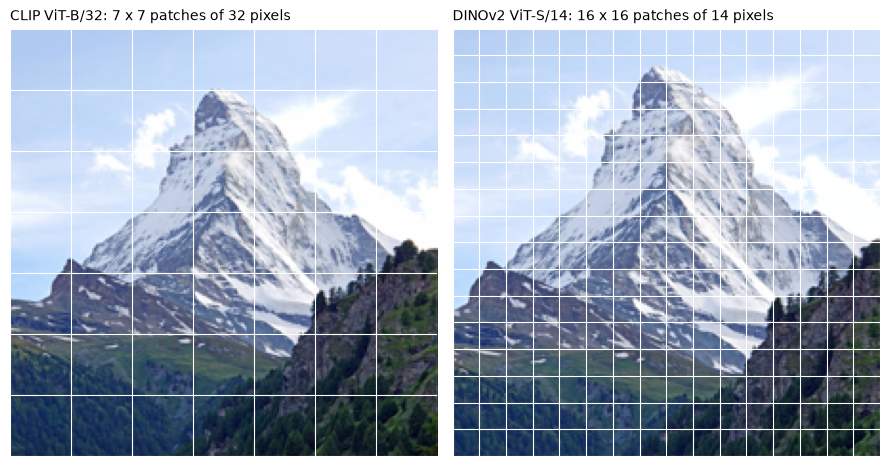

In [11]:
def model_input(processor, im):
    p = processor if hasattr(processor, "image_mean") else processor.image_processor
    x = p(images=im, return_tensors="pt")["pixel_values"][0].numpy().transpose(1, 2, 0)
    return np.clip(x * np.array(p.image_std) + np.array(p.image_mean), 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, (name, processor, patch) in zip(axes, [("CLIP ViT-B/32", E.clip_processor, E.clip_model.config.vision_config.patch_size),
                                               ("DINOv2 ViT-S/14", E.dino_processor, E.dino_model.config.patch_size)]):
    x = model_input(processor, query)
    ax.imshow(x)
    for t in range(0, x.shape[0] + 1, patch):
        ax.axhline(t - 0.5, color="white", lw=0.8)
        ax.axvline(t - 0.5, color="white", lw=0.8)
    ax.set_title(f"{name}: {x.shape[0] // patch} x {x.shape[0] // patch} patches of {patch} pixels", fontsize=10, loc="left")
    ax.axis("off")
plt.tight_layout()
plt.show()

### CLIP: a batch of three pairs

CLIP trains an image encoder and a text encoder side by side on image-caption pairs. Each training
step computes the cosine similarity of every image with every caption in a batch and treats each
row and each column as a classification task:

$$\mathcal{L} = -\frac{1}{2N} \sum_{i=1}^{N} \left( \log \frac{e^{s_{i,i}}}{\sum_{j=1}^{N} e^{s_{i,j}}} + \log \frac{e^{s_{i,i}}}{\sum_{j=1}^{N} e^{s_{j,i}}} \right) \quad \text{with} \quad s_{i,j} = \frac{\cos(\mathbf{v}_i, \mathbf{t}_j)}{\tau}$$

The book's batch has three photos with web-style captions. The temperature $\tau$ is learned
during training and stored in the model.

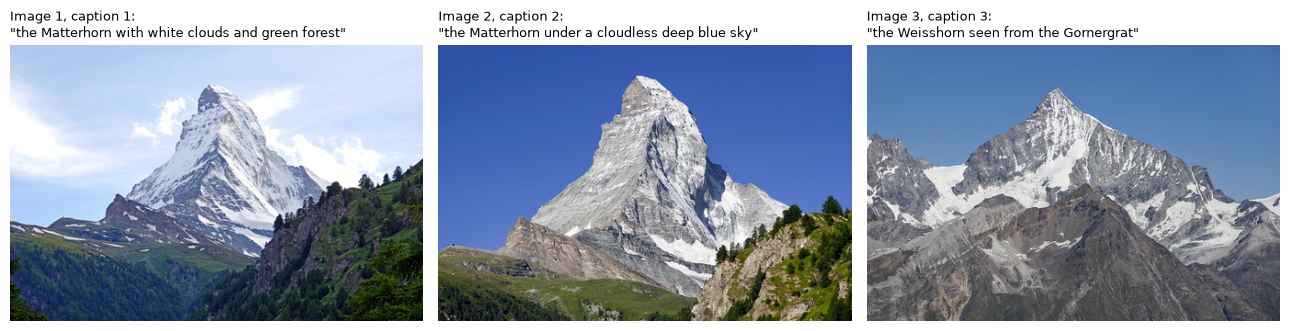

| Cosine similarity   |   caption 1 |   caption 2 |   caption 3 |
|:--------------------|------------:|------------:|------------:|
| image 1             |      0.3266 |      0.2892 |      0.2996 |
| image 2             |      0.3274 |      0.3136 |      0.2984 |
| image 3             |      0.2748 |      0.2747 |      0.3285 |

Temperature stored in the model: $\tau$ = **0.0100**.

In [12]:
batch = [(query, "the Matterhorn with white clouds and green forest"),
         (images[ids.index("matterhorn_zermatt")], "the Matterhorn under a cloudless deep blue sky"),
         (images[ids.index("weisshorn_gornergrat")], "the Weisshorn seen from the Gornergrat")]
tau = float(1 / E.clip_model.logit_scale.detach().exp())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for c, (ax, (im, caption)) in enumerate(zip(axes, batch), 1):
    ax.imshow(crop_32(im, (450, 300)))
    ax.set_title(f"Image {c}, caption {c}:\n\"{caption}\"", fontsize=9, loc="left")
    ax.axis("off")
plt.tight_layout()
plt.show()

V = np.array([E.clip_image(im) for im, _ in batch])
T = np.array([E.clip_text(caption) for _, caption in batch])
C = np.round(V @ T.T, 4)                                            # rounded to four decimals, as in the book
print_table([[f"image {i + 1}"] + list(C[i]) for i in range(3)],
            headers=["Cosine similarity", "caption 1", "caption 2", "caption 3"], floatfmt=".4f")
display_md(f"Temperature stored in the model: $\\tau$ = **{tau:.4f}**.")

Each row becomes a softmax over the captions, each column a softmax over the images:

In [13]:
S = C / tau

def softmax(x, axis):
    x = np.exp(x - x.max(axis=axis, keepdims=True))
    return x / x.sum(axis=axis, keepdims=True)

p_caption = np.diag(softmax(S, axis=1))         # each image: probability of its own caption
p_image = np.diag(softmax(S, axis=0))           # each caption: probability of its own image
loss = -(np.log(p_caption).sum() + np.log(p_image).sum()) / (2 * len(S))
print_table([[f"pair {i + 1}", p_caption[i], -np.log(p_caption[i]), p_image[i], -np.log(p_image[i])] for i in range(3)],
            headers=["Pair", "P(own caption \\| image)", "Loss term (row)", "P(own image \\| caption)", "Loss term (column)"],
            floatfmt=("", ".2%", ".3f", ".2%", ".3f"))
display_md(f"Batch loss: **{loss:.3f}**. With untrained encoders, all similarities would be about equal, "
           f"every probability 1/3, and the loss $\\ln 3$ = {np.log(3):.3f}.")

| Pair   |   P(own caption \| image) |   Loss term (row) |   P(own image \| caption) |   Loss term (column) |
|:-------|--------------------------:|------------------:|--------------------------:|---------------------:|
| pair 1 |                    91.66% |             0.087 |                    47.87% |                0.737 |
| pair 2 |                    19.25% |             1.647 |                    90.28% |                0.102 |
| pair 3 |                    99.08% |             0.009 |                    90.51% |                0.100 |

Batch loss: **0.447**. With untrained encoders, all similarities would be about equal, every probability 1/3, and the loss $\ln 3$ = 1.099.

The Zermatt photo gives its own caption only about 19%, because it is slightly closer to the
caption of the query. In the column direction, caption 1 is even closer to the Zermatt photo than
to its own image. A training step on this batch would pull the Zermatt photo toward its own
caption and push it away from caption 1. The values match the book.

The similarities between images and texts are low: even the matching pairs reach only about 0.33.
Two images are much more similar to each other:

In [14]:
v_q = E.clip_image(query)
display_md(f"CLIP cosine similarity of the query image with the Taj Mahal photo: **{v_q @ E.clip_image(photos['taj_mahal']):.3f}**, "
           f"higher than any image-caption pair of the batch.")

CLIP cosine similarity of the query image with the Taj Mahal photo: **0.655**, higher than any image-caption pair of the batch.

What carries the information is the difference between candidates, which the temperature
amplifies: a difference of 0.014 in cosine similarity, 0.3274 against 0.3136, becomes a factor of
about $e^{1.38} \approx 4$ in probability.

### Near-duplicates

Near-duplicate detection finds copies of an image that were resized, recompressed, cropped, or
edited. We edit the Matterhorn photo in six ways and compare each copy with the original. For
contrast, we also compare the Taj Mahal and Federer photos.

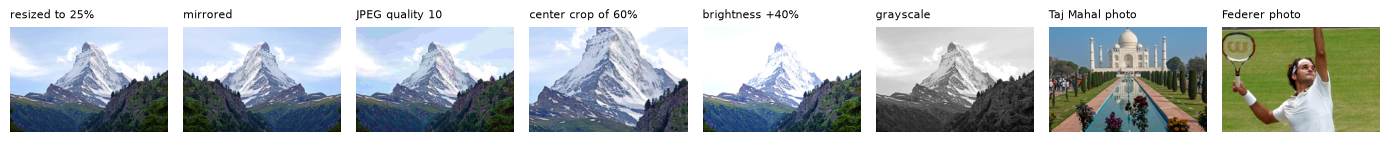

| Copy of the Matterhorn photo   |   CLIP cosine |   DINOv2 cosine |   ResNet-18 cosine |   Histogram L1 |
|:-------------------------------|--------------:|----------------:|-------------------:|---------------:|
| resized to 25%                 |         0.998 |           0.994 |              0.995 |          0.061 |
| mirrored                       |         0.997 |           0.985 |              0.969 |          0.000 |
| JPEG quality 10                |         0.900 |           0.967 |              0.971 |          0.464 |
| center crop of 60%             |         0.964 |           0.946 |              0.939 |          0.494 |
| brightness +40%                |         0.969 |           0.977 |              0.959 |          1.065 |
| grayscale                      |         0.922 |           0.974 |              0.920 |          1.415 |
| Taj Mahal photo                |         0.655 |           0.070 |              0.487 |          1.361 |
| Federer photo                  |         0.465 |           0.015 |              0.449 |          1.659 |

In [15]:
def jpeg(im, quality):
    import io
    buf = io.BytesIO()
    im.save(buf, "JPEG", quality=quality)
    return Image.open(io.BytesIO(buf.getvalue())).convert("RGB")

w, h = query.size
copies = {
    "resized to 25%": query.resize((w // 4, h // 4), Image.LANCZOS),
    "mirrored": ImageOps.mirror(query),
    "JPEG quality 10": jpeg(query, 10),
    "center crop of 60%": query.crop((int(w * .2), int(h * .2), int(w * .8), int(h * .8))),
    "brightness +40%": ImageEnhance.Brightness(query).enhance(1.4),
    "grayscale": ImageOps.grayscale(query).convert("RGB"),
    "Taj Mahal photo": photos["taj_mahal"],
    "Federer photo": photos["federer"],
}
fig, axes = plt.subplots(1, len(copies), figsize=(14, 1.6))
for ax, (name, im) in zip(axes, copies.items()):
    shown_im = im.resize(query.size, Image.NEAREST) if name == "resized to 25%" else im    # show the lost detail
    ax.imshow(crop_32(shown_im, (240, 160)))
    ax.set_title(name, fontsize=8, loc="left")
    ax.axis("off")
plt.tight_layout()
plt.show()

ref = (E.clip_image(query), E.dino_image(query), E.resnet(query), lab_histogram(np.asarray(query)))
rows = []
for name, im in copies.items():
    v = (E.clip_image(im), E.dino_image(im), E.resnet(im), lab_histogram(np.asarray(im)))
    rows.append([name, ref[0] @ v[0], ref[1] @ v[1], ref[2] @ v[2], np.abs(ref[3] - v[3]).sum()])
print_table(rows, headers=["Copy of the Matterhorn photo", "CLIP cosine", "DINOv2 cosine", "ResNet-18 cosine",
                           "Histogram L1"], floatfmt=".3f")

DINOv2 separates the two groups most clearly: every copy scores high, both other photos score
close to 0, so any threshold between them works. CLIP keeps all copies high too, with the heavily
compressed copy at the bottom, but the Taj Mahal reaches a value well above 0.5, so the margin is
smaller. The histogram fails on global edits: the grayscale copy is farther from the original
than the Taj Mahal photo. Each model has its own range of values, so a threshold chosen for one
model is meaningless for another.

## Payoff: Then vs. Now

We send the Matterhorn query to the 45 photos with every method of the chapter. The color
histogram uses the quadratic distance, SIFT the number of matches that pass the ratio test and the
geometric check (demo ch10-03), and ResNet-18, DINOv2, and CLIP the cosine similarity of their
embeddings. A result is relevant if it shows the Matterhorn, or, more generously, any mountain.

In [16]:
t0 = time.perf_counter()
V_dino = np.array([E.dino_image(im) for im in images])
V_clip = np.array([E.clip_image(im) for im in images])
sift_q = sift_features(np.asarray(query))
s_sift = np.array([sift_score(sift_q, sift_features(np.asarray(im)))[1] for im in images], float)
scores = {
    "Color histogram (Lab, quadratic)": s_hist,
    "SIFT (ratio test, geometric check)": s_sift,
    "ResNet-18 embedding": s_res,
    "DINOv2 embedding": V_dino @ E.dino_image(query),
    "CLIP image embedding": V_clip @ v_q,
}
display_md(f"Features of all 45 photos computed in {time.perf_counter() - t0:.0f} seconds.")

def top(s, k=5):
    return np.argsort(-s, kind="stable")[:k]

zermatt = ids.index("matterhorn_zermatt")
print_table([[name, sum(collection[i]["is_matterhorn"] for i in top(s)) / 5, sum(collection[i]["is_mountain"] for i in top(s)) / 5,
              rank_of(s, zermatt)] for name, s in scores.items()],
            headers=["Method", "P@5 Matterhorn", "P@5 mountain", "Rank of the photo from nearly the same spot"],
            floatfmt=".1f")

Features of all 45 photos computed in 35 seconds.

| Method                             |   P@5 Matterhorn |   P@5 mountain |   Rank of the photo from nearly the same spot |
|:-----------------------------------|-----------------:|---------------:|----------------------------------------------:|
| Color histogram (Lab, quadratic)   |              0.2 |            0.8 |                                            26 |
| SIFT (ratio test, geometric check) |              0.2 |            0.4 |                                             1 |
| ResNet-18 embedding                |              0.6 |            1.0 |                                             6 |
| DINOv2 embedding                   |              0.6 |            1.0 |                                             1 |
| CLIP image embedding               |              0.8 |            1.0 |                                             1 |

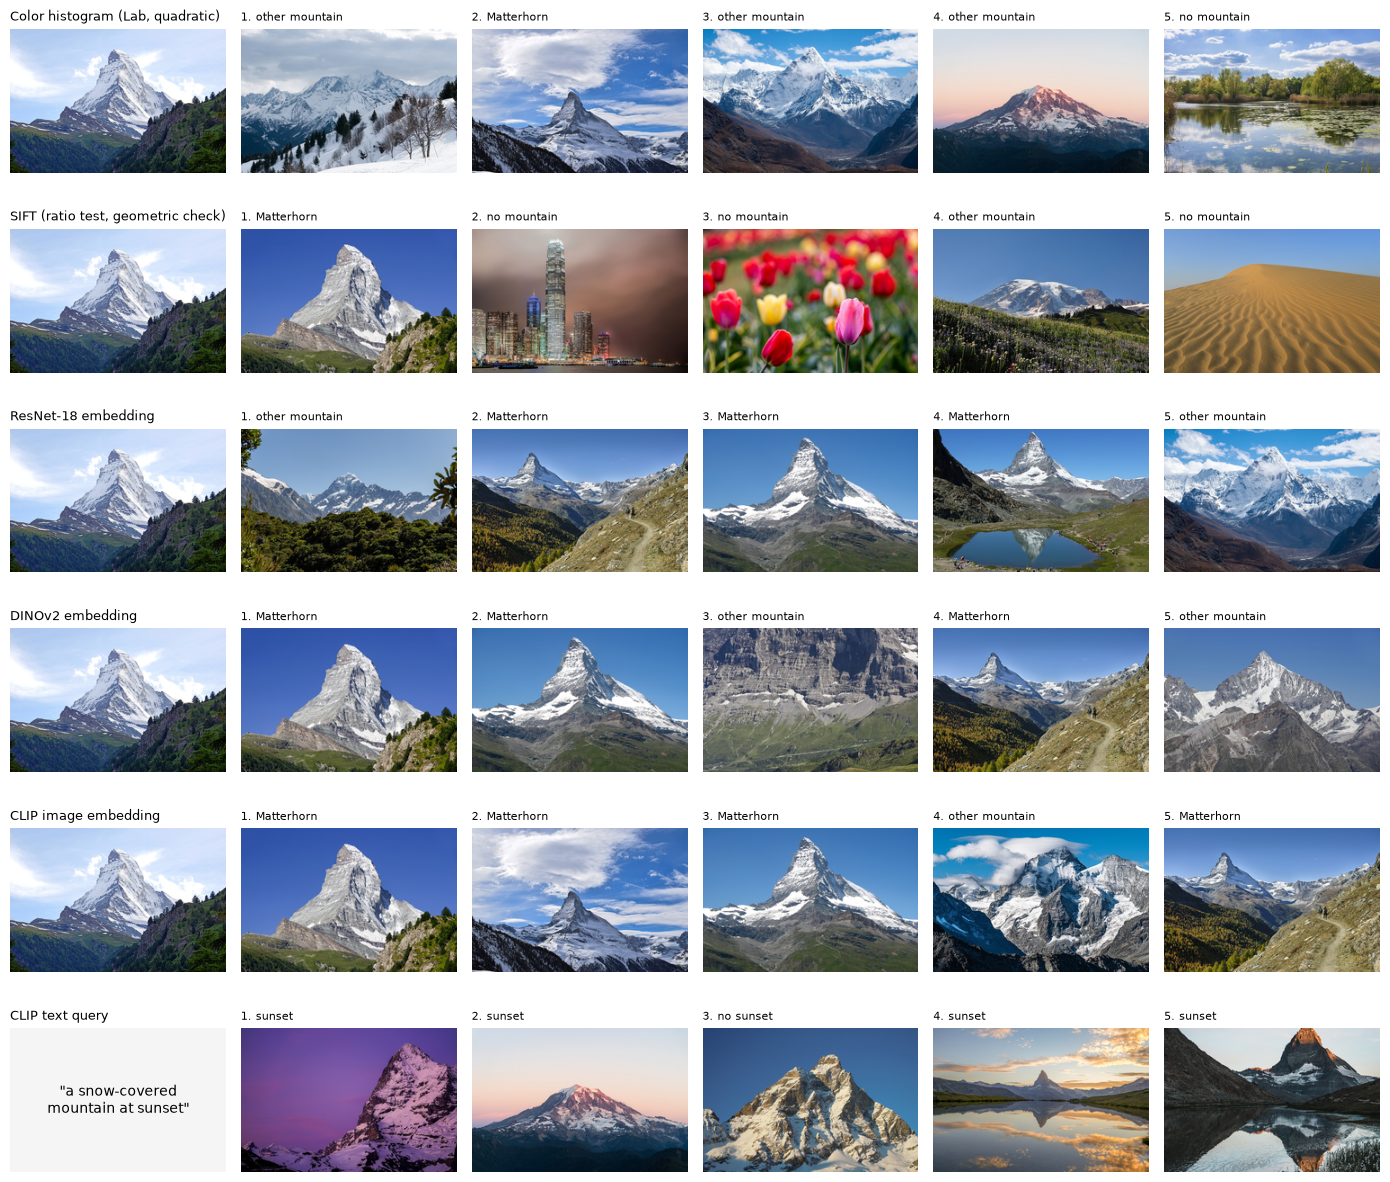

In [17]:
SUNSET = "a snow-covered mountain at sunset"
s_text = V_clip @ E.clip_text(SUNSET)

def is_sunset(it):
    return it["is_mountain"] and bool({"sunset", "alpenglow"} & set(it["tags"]))

def label(it, text=False):
    if text:
        return "sunset" if is_sunset(it) else "no sunset"
    return "Matterhorn" if it["is_matterhorn"] else "other mountain" if it["is_mountain"] else "no mountain"

rows = [(name, s, False) for name, s in scores.items()] + [("CLIP text query", s_text, True)]
fig, axes = plt.subplots(len(rows), 6, figsize=(14, 2.05 * len(rows)))
for r, (name, s, text) in enumerate(rows):
    axes[r, 0].imshow(np.full((200, 300, 3), 245, np.uint8) if text else crop_32(query))
    if text:
        axes[r, 0].text(150, 100, textwrap.fill(f'"{SUNSET}"', 20), ha="center", va="center", fontsize=10)
    axes[r, 0].set_title(name, fontsize=9, loc="left")
    for c, i in enumerate(top(s), 1):
        axes[r, c].imshow(crop_32(images[i], (240, 160)))
        axes[r, c].set_title(f"{c}. {label(collection[i], text)}", fontsize=8, loc="left")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

Each method fails in its own way:

- **The color histogram** returns mountains because snow and sky are typical of mountain photos in
  this collection, but the ranking follows the palette: the photo from nearly the same spot lands
  far down because its sky is a deeper blue.
- **SIFT** is all or nothing. The photo from nearly the same spot comes first; the rest of its
  ranking is noise.
- **ResNet-18** returns five mountains, but its first result is Aoraki / Mount Cook. It knows
  "alp", but not which one.
- **DINOv2** puts the near-identical photo first, followed by more views of the Matterhorn and the
  most similar-looking other peaks. It compares how the images look, in detail.
- **CLIP** returns the most Matterhorn photos, including views in other seasons. A plausible
  explanation is its training: captions on the web name landmarks, and the Matterhorn is among the
  most photographed mountains.

### Text queries

The text query shows what none of the other methods can do. We count a result as relevant for
the sunset query if it shows a mountain at sunset or in alpenglow.

In [18]:
def text_search(text, k=5):
    """Rank the collection by the CLIP similarity of the text and the images."""
    s = V_clip @ E.clip_text(text)
    return [(ids[i], s[i]) for i in top(s, k)]

relevant = sum(is_sunset(it) for it in collection)
display_md(f'"{SUNSET}": P@5 = **{sum(is_sunset(collection[i]) for i in top(s_text)) / 5:.1f}**; '
           f"the collection has {relevant} relevant photos, so {min(relevant, 5) / 5:.1f} is the maximum possible.")
TEXTS = ["a pyramid-shaped peak above a pine forest", SUNSET, "a sailboat on a lake", "a city at night"]
print_table([[t] + [f"{cid} ({s:.3f})" for cid, s in text_search(t, 3)] for t in TEXTS],
            headers=["Text query", "1", "2", "3"])

"a snow-covered mountain at sunset": P@5 = **0.8**; the collection has 4 relevant photos, so 0.8 is the maximum possible.

| Text query                                | 1                             | 2                                   | 3                                   |
|:------------------------------------------|:------------------------------|:------------------------------------|:------------------------------------|
| a pyramid-shaped peak above a pine forest | matterhorn_zermatt (0.296)    | weisshorn_gornergrat (0.290)        | aoraki_mount_cook (0.285)           |
| a snow-covered mountain at sunset         | eiger_sunset (0.314)          | rainier_alpenglow (0.311)           | matterhorn_cervinia (0.293)         |
| a sailboat on a lake                      | decoy_sailboats_aasee (0.293) | decoy_lake_trees_reflection (0.277) | matterhorn_stellisee_sunset (0.256) |
| a city at night                           | city_night_hong_kong (0.258)  | city_night_st_louis (0.226)         | notre_dame_portals (0.217)          |

All relevant sunset photos appear in the top 5. The remaining result shows the south side of the
Matterhorn in warm low-angle light, which many users would accept as well. The similarity values
are as low as expected for pairs of a text and an image. The sailboat photo and both night
skylines come first for their queries.

### Linear probe and cost

The linear probe of Part 1 on the transformer embeddings, and the time each method needs per
image on this computer:

In [19]:
probe["DINOv2 embedding (384)"] = linear_probe(V_dino)
probe["CLIP image embedding (512)"] = linear_probe(V_clip)
print_table([[name, mean_acc, worst] for name, (mean_acc, worst) in probe.items()],
            headers=["Features", "Mean accuracy (50 draws)", "Worst draw"], floatfmt=".1%")

| Features                   |   Mean accuracy (50 draws) |   Worst draw |
|:---------------------------|---------------------------:|-------------:|
| Color histogram (125 bins) |                      68.9% |        51.3% |
| ResNet-18 embedding (512)  |                      98.1% |        92.3% |
| DINOv2 embedding (384)     |                      99.1% |        94.9% |
| CLIP image embedding (512) |                      95.2% |        82.1% |

In [20]:
def median_ms(fn, inputs):
    times = []
    for x in inputs:
        t0 = time.perf_counter()
        fn(x)
        times.append(1000 * (time.perf_counter() - t0))
    return np.median(times)

sample = images[::3]                                                # every third photo, to save time
thumbs = [np.asarray(im.resize((320, round(320 * im.height / im.width)), Image.LANCZOS)) for im in sample]
HIST = "Color histogram (125 bins, 320-pixel thumbnail)"
cost = {HIST: median_ms(lab_histogram_fast, thumbs),
        "SIFT (full photo)": median_ms(lambda im: sift_features(np.asarray(im)), sample),
        "ResNet-18": median_ms(E.resnet, sample),
        "CLIP image encoder": median_ms(E.clip_image, sample),
        "DINOv2": median_ms(E.dino_image, sample)}
print_table([[name, ms, ms / cost[HIST]] for name, ms in cost.items()],
            headers=["Method", "Milliseconds per image (median)", "Times the histogram"], floatfmt=("", ".1f", ".0f"))
diff = max(np.abs(lab_histogram_fast(t) - lab_histogram(t)).sum() for t in thumbs)
display_md(f"The histogram is timed with OpenCV's color conversion (`lab_histogram_fast`), as in the book; "
           f"its histograms differ from those of the NumPy formulas by an L1 distance of at most {diff:.3f}.")

| Method                                          |   Milliseconds per image (median) |   Times the histogram |
|:------------------------------------------------|----------------------------------:|----------------------:|
| Color histogram (125 bins, 320-pixel thumbnail) |                               7.5 |                     1 |
| SIFT (full photo)                               |                             192.8 |                    26 |
| ResNet-18                                       |                              68.6 |                     9 |
| CLIP image encoder                              |                             158.3 |                    21 |
| DINOv2                                          |                             138.6 |                    19 |

The histogram is timed with OpenCV's color conversion (`lab_histogram_fast`), as in the book; its histograms differ from those of the NumPy formulas by an L1 distance of at most 0.024.

The timings depend on the computer and vary between runs. The order of magnitude is stable: the
histogram needs no model and is by far the cheapest; every neural network costs one forward pass
per image, and SIFT works on the full photo.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Each generation of features answers a different question</strong><br>
The color histogram finds the palette, SIFT the same scene, ResNet-18 the category, DINOv2 the same look in detail, and CLIP the same concept, including from a text. The newer features generalize far better, but the classical ones still win for exact color constraints, for proof that two photos show the same object, for explanations, and for cost. Current systems combine both worlds.
</div>

## Summary

- The first layer of ResNet-18 learns edge, stripe, and color-opponent filters by itself. Later
  stages respond to larger and more abstract patterns.
- Global average pooling over the last stage gives a 512-dimensional embedding; earlier stages
  make every photo look alike.
- The embedding of a classifier separates categories, not instances: a peak in New Zealand
  outranks a photo of the same mountain. A linear probe adapts it to a new task with six labeled
  photos.
- CLIP is trained with a contrastive loss on image-caption pairs. Image-text similarities are low
  (about 0.1 to 0.4); differences between candidates carry the information.
- DINOv2 separates near-duplicates from other photos most clearly. Similarity values do not
  transfer between models.
- On the Matterhorn query, each method fails in its own way, and only CLIP can answer text queries.

## Try it yourself

1. **Your own text query.** Call `text_search("...")` with queries of your own, such as "a red
   animal", "a building with a dome", or "something to eat". Where does CLIP succeed, and where
   does it fail?
2. **Zero-shot classification.** Compare the CLIP image embedding of a few photos with the text
   embeddings of prompts such as "a photo of a mountain", "a photo of a building", and "a photo of
   a person", and pick the closest prompt for each photo.
3. **A harder probe.** Change the task of `linear_probe` to "Matterhorn or not"
   (`y = np.array([it["is_matterhorn"] for it in collection], int)`). Which embedding separates
   one mountain from other mountains best?